# Industrial Surface Defect Classification using Transfer Learning

## Objective

The aim of this notebook is to automatically classify surface defects in steel materials using real-world industrial image data and a transfer learning approach.

Surface defects such as cracks, scratches, inclusions, and pits commonly occur during manufacturing processes and can significantly affect product quality. Manual inspection of these defects is time-consuming, inconsistent, and difficult to scale.

In this notebook, we use a dataset containing steel surface images belonging to six different defect categories:
- Crazing  
- Inclusion  
- Patches  
- Pitted Surface  
- Rolled-in Scale  
- Scratches  

All defect types originate from the same manufacturing domain, and learning from all categories together allows the model to capture shared texture and structural patterns present across industrial surfaces.

The problem statement for this notebook is:

> **Given a steel surface image, predict the type of surface defect present in the image using a pretrained convolutional neural network.**

To solve this problem efficiently, we apply **transfer learning** by reusing a pretrained `MobileNetV2` model as a feature extractor and training only a lightweight classification head. This demonstrates how deep learning models can be adapted to real industrial use cases using limited data and computational resources.

## Business Value

In manufacturing industries such as steel, automotive, and heavy engineering, surface defects can directly impact product quality, safety, customer satisfaction, production cost, and rework rates.

Traditional inspection methods rely heavily on human inspectors, which introduces inconsistency in defect detection. Manual inspection also comes with high operational costs and scalability limitations.

By applying transfer learning, organisations can:
- Reuse pretrained visual intelligence instead of training models from scratch  
- Reduce development and training time  
- Achieve reliable defect detection even with smaller datasets  
- Deploy lightweight models suitable for real-time or edge-based inspection systems

## Dataset Description

This notebook uses the **NEU Surface Defect Dataset**, a real-world industrial dataset commonly used in manufacturing research and automated inspection systems.

### Dataset Characteristics:
- Images represent steel surface textures captured under industrial conditions  
- Each image belongs to one of six defect categories:
  - Crazing  
  - Inclusion  
  - Patches  
  - Pitted Surface  
  - Rolled-in Scale  
  - Scratches  
- Images are originally grayscale
- The dataset is reasonably balanced across classes  


#### Why this dataset?

- It represents a real industrial computer vision problem
- Defect patterns are texture-based, making it ideal for demonstrating transfer learning  
- The dataset size is moderate, encouraging the use of **partial transfer learning** rather than full model retraining  

## Flow Diagram

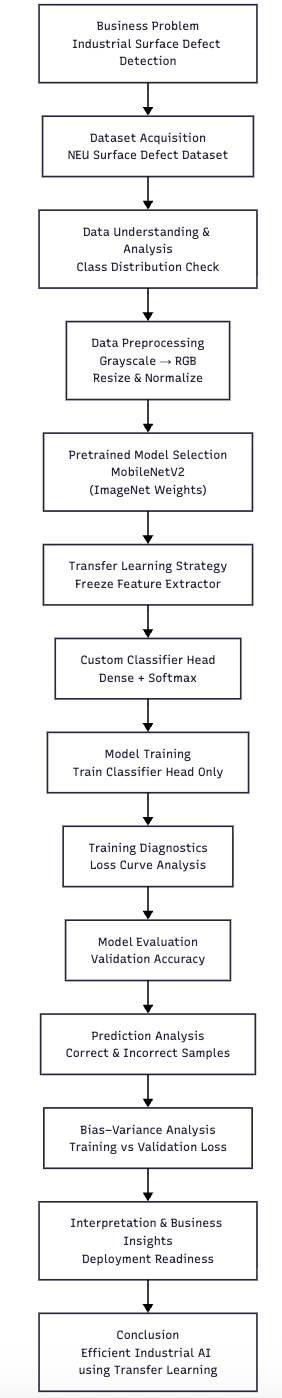

**Note:** You are free to choose any pre-trained model from the available ones. However, the architecture we suggest for this notebook is `MobileNetV2` with "ImageNet" weights.

The choice of libraries, frameworks, and backbones for this notebook are up to you. Before starting this notebook, please ensure that your environment meets the following requirements.


**Software Requirements**

- *Python version*: > Python3.11  
- *Execution environment*: Jupyter Notebook / JupyterLab / VS Code Notebook  
- *Operating system*: macOS, Linux, or Windows  


**Hardware Requirements**
- A GPU-powered training would be optimal, and would require installation of proper libraries and CUDA
- However, CPU-only execution might also be sufficient, and would work without CUDA

### Import Necessary libraries

In [33]:
# Import Required Libraries
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Input, Lambda
from tensorflow.keras.models import Model
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

In [34]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Data Loading and Preparation

<font color=red></font>

In any machine learning workflow, understanding and preparing the data correctly is a critical first step. Before building a deep learning model, it is important
to examine how the dataset is structured, how labels are assigned, and how images are preprocessed for training.

This section includes the following steps:
- Understanding the dataset organisation
- Verifying class labels and distributions
- Applying appropriate image transformations for transfer learning
- Development of train loader and validation loader

### 1.1 Dataset Understanding and Structure

<font color=red></font>

The NEU Surface Defect Dataset consists of real-world grayscale images collected from steel manufacturing processes. Each image belongs to one of six surface defect categories.

The dataset is already split into **training** and **validation** sets, and images are organised into class-specific folders. This structure allows us to use PyTorch’s `ImageFolder` utility, which automatically assigns labels based on directory names.

The same directory-based structure is also compatible with TensorFlow, allowing the dataset to be loaded directly using `tf.keras.utils.image_dataset_from_directory`, which infers class labels from folder names in a similar manner.



Before proceeding, we load the dataset and verify:
- Number of images in training and validation sets
- Mapping between class names and numeric labels

#### **1.1.1** Load Images and Labels  <font color=red></font>

Load the training and validation datasets and check the number of images and the number of categories present

In [35]:
# Load training and validation images + labels

# Set paths to dataset directories
train_dir = "/content/drive/MyDrive/Colab Notebooks/NEU-DET/train/images"
val_dir = "/content/drive/MyDrive/Colab Notebooks/NEU-DET/validation/images"

BATCH_SIZE = 32
IMG_SIZE = (224, 224)

# Load training and validation images + labels
train_ds = image_dataset_from_directory(
    train_dir,
    labels="inferred",
    label_mode="categorical",
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=True,
    seed=42,
)

val_ds = image_dataset_from_directory(
    val_dir,
    labels="inferred",
    label_mode="categorical",
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=False,
)

# Dataset statistics
class_names = train_ds.class_names
num_classes = len(class_names)
num_train_images = len(train_ds.file_paths)
num_val_images = len(val_ds.file_paths)

print(f"Number of categories: {num_classes}")
print(f"Classes: {class_names}")
print(f"Number of training images: {num_train_images}")
print(f"Number of validation images: {num_val_images}")


Found 1441 files belonging to 6 classes.
Found 360 files belonging to 6 classes.
Number of categories: 6
Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Number of training images: 1441
Number of validation images: 360


Here, the image loader automatically assigns numeric labels based on folder names. For example, all images inside the "crazing" folder receive the same label.

This approach reduces manual labeling effort and ensures consistency between directory structure and class definitions.

#### **1.1.2** Check and Visualise Class Distribution <font color=red></font>

In [36]:
# Dataset Class Distribution
import os

train_class_counts = {}
for cls in class_names:
    class_path = os.path.join(train_dir, cls)
    train_class_counts[cls] = len(os.listdir(class_path))

val_class_counts = {}
for cls in class_names:
    class_path = os.path.join(val_dir, cls)
    val_class_counts[cls] = len(os.listdir(class_path))

print("Training Set Class Distribution:")
for cls, count in train_class_counts.items():
    print(f"{cls}: {count}")

print("\nValidation Set Class Distribution:")
for cls, count in val_class_counts.items():
    print(f"{cls}: {count}")

Training Set Class Distribution:
crazing: 240
inclusion: 240
patches: 241
pitted_surface: 240
rolled-in_scale: 240
scratches: 240

Validation Set Class Distribution:
crazing: 60
inclusion: 60
patches: 60
pitted_surface: 60
rolled-in_scale: 60
scratches: 60


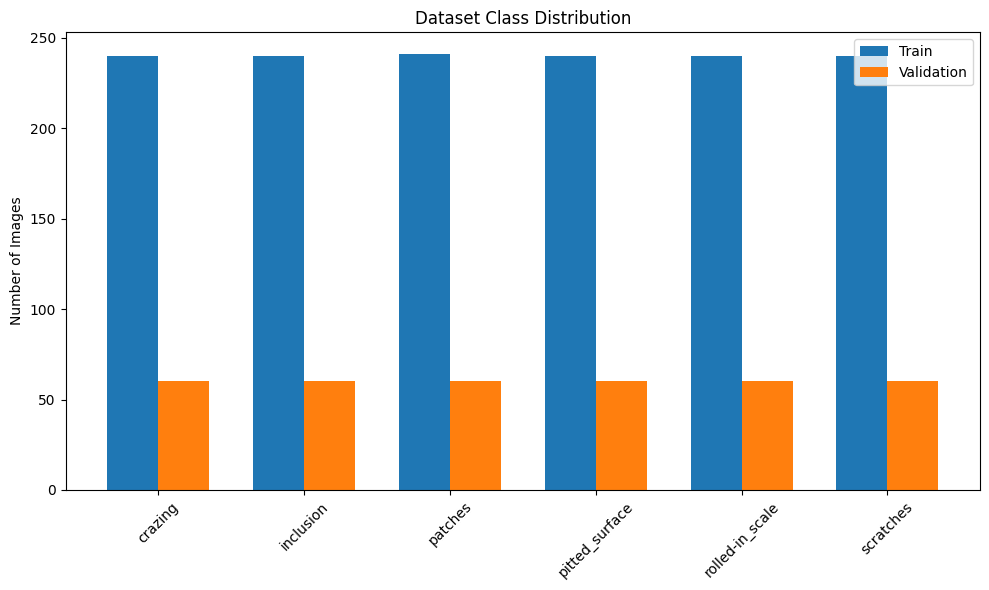

In [37]:
# Visualise class distribution
# Visualise class distribution
import matplotlib.pyplot as plt
import numpy as np

labels = list(train_class_counts.keys())
train_counts = list(train_class_counts.values())
val_counts = list(val_class_counts.values())

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width/2, train_counts, width, label='Train')
ax.bar(x + width/2, val_counts, width, label='Validation')

ax.set_ylabel('Number of Images')
ax.set_title('Dataset Class Distribution')
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45)
ax.legend()

plt.tight_layout()
plt.show()

### 1.2 Data Preprocessing and Transformations

<font color=red></font>

Deep learning models pretrained on ImageNet expect images to be in a specific format. Although the NEU dataset images are grayscale, ImageNet-pretrained models require 3-channel RGB images with standardised dimensions and normalisation.

#### **1.2.1** Apply Image Transformations <font color=red></font>

To ensure compatibility, we apply the following transformations:
- Convert grayscale images to RGB
- Resize images to a fixed resolution
- Normalize using ImageNet mean and standard deviation

These transformations are provided in [`transforms`](https://docs.pytorch.org/vision/0.24/transforms.html) from `torchvision`, while in TensorFlow the same preprocessing steps are applied using [`tf.image`](https://www.tensorflow.org/api_docs/python/tf/image) operations and `tf.keras.layers` within the input pipeline.

In PyTorch, normalization can be performed using `Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)`.

In TensorFlow, the same effect is achieved by explicitly standardising the images with the ImageNet statistics, i.e. subtracting `IMAGENET_MEAN` and dividing by `IMAGENET_STD` using `tf.image` operations or a custom `tf.keras.layers.Layer` within the preprocessing pipeline.

In [38]:
# Image Transformations
# Image Transformations

IMAGENET_MEAN = tf.constant([0.485, 0.456, 0.406], dtype=tf.float32)
IMAGENET_STD = tf.constant([0.229, 0.224, 0.225], dtype=tf.float32)

def image_preprocessing(image, label):
    # Convert pixel values from [0, 255] to [0, 1]
    image = tf.cast(image, tf.float32) / 255.0

    # Standardise using ImageNet mean and standard deviation
    image = (image - IMAGENET_MEAN) / IMAGENET_STD

    return image, label


At this stage, the dataset is fully prepared for training a transfer learning model. Images are correctly formatted, normalized, and labeled, ensuring a smooth transition into model design and training.

#### **1.2.2** Create DataLoaders for both the training and validation datasets <font color=red></font>


Deep learning models are trained on data in **batches** rather than loading the entire dataset into memory at once.

PyTorch provides the [`DataLoader`](https://docs.pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader) utility to batch the data, shuffle training samples and load data efficiently during training. For Tensorflow, you can use similar functionality provided by [`tf.data.Dataset` API](https://www.tensorflow.org/api_docs/python/tf/data/Dataset), which supports efficient batching, shuffling, prefetching, and parallel data loading within the input pipeline.

In [39]:
# DataLoader Creation
AUTOTUNE = tf.data.AUTOTUNE

train_loader = train_ds.map(image_preprocessing, num_parallel_calls=AUTOTUNE)
train_loader = train_loader.cache().prefetch(buffer_size=AUTOTUNE)

val_loader = val_ds.map(image_preprocessing, num_parallel_calls=AUTOTUNE)
val_loader = val_loader.cache().prefetch(buffer_size=AUTOTUNE)

Also decide on where to use shuffling - training or validation

## 2. Transferring Knowledge and Model Training

<font color=red></font>

Training deep learning models from scratch requires large amounts of labeled data and computational resources. In many real-world scenarios, this is not feasible. Transfer learning addresses this challenge by reusing knowledge learned from a large source dataset (such as ImageNet) and adapting it to a new, related task.

### 2.1 Pretrained Model Selection

<font color=red></font>

For this notebook, we will prefer **MobileNetV2**, a lightweight convolutional neural network pretrained on the ImageNet dataset. Though any pre-trained network will suit the task.

MobileNetV2 is computationally efficient and lightweight. It performs well on texture-based image classification tasks.

In this section:
- Select a suitable pretrained convolutional neural network
- Apply a partial transfer learning strategy
- Design a task-specific classifier for surface defect detection

#### **2.1.1** Load the Pre-Trained Model <font color=red></font>

Load the pre-trained model of your choice. If you wish to use a different architecture from MobileNet, also explain the reason for your choice.

In [40]:
# Load Pretrained Network
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

The MobileNetV2 architecture consists of two main components:
- A **feature extractor** that learns visual representations
- A **classifier head** originally designed for ImageNet’s 1000 classes

#### **2.1.2** Freezing Strategy and Classifier Design <font color=red></font>

Build the transfer learning model by loading and freezing the feature extractor layers.


Instead of retraining the entire network, we apply partial transfer learning. In this approach the pretrained feature extractor is frozen and only the classifier head is retrained for the new task. This strategy reduces the risk of overfitting and speeds up training.

In [41]:
# Build Transfer Learning Model
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)

model = tf.keras.Model(inputs=inputs, outputs=outputs)


#### **2.1.3** Verify the final frozen and trainable parameters <font color=red></font>

In [ ]:
# Verify Freezing Strategy
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 2.2 Model Training

<font color=red></font>

After designing the transfer learning model, the next step is to train it on the prepared dataset.

We only train the classifier head, while the pretrained feature extractor remains frozen. This allows the model to adapt quickly to the surface defect classification task.

In this section, we:
- Configure the training setup
- Train the model for a small number of epochs
- Track training loss to verify learning progress

#### **2.2.1** Training Configuration <font color=red></font>

Before starting the training loop, we define:
- The computation device: CPU or GPU
- The loss function: Use a suitable loss function (one of the cross-entropy losses would work fine here)
- The optimizer: preferably [Adam](https://arxiv.org/abs/1412.6980) from [Tensorflow](https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Adam) or [Pytorch](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html)

These components control how the model learns from data and how its parameters are updated during training.

In [43]:
# Training Configuration
# Define the optimizer (Adam)
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

# Define the loss function (Categorical Crossentropy)
loss_fn = tf.keras.losses.CategoricalCrossentropy()

# Compile the model
model.compile(
    optimizer=optimizer,
    loss=loss_fn,
    metrics=['accuracy']
)

#### **2.2.2** Model Training Loop <font color=red></font>

Perform the training and track the training loss across epochs to verify whether the model is learning effectively.

The training loop iterates over the dataset multiple times (epochs). For each batch of images, the model:
- Performs a forward pass
- Computes the loss
- Updates the trainable parameters using backpropagation

In [44]:
# Model Training
EPOCHS = 10

history = model.fit(
    train_loader,
    validation_data=val_loader,
    epochs=EPOCHS
)

Epoch 1/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 112s 2s/step - accuracy: 0.8300 - loss: 0.5985 - val_accuracy: 0.9278 - val_loss: 0.2886
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step - accuracy: 0.9833 - loss: 0.1021 - val_accuracy: 0.9611 - val_loss: 0.1680
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 78s 2s/step - accuracy: 0.9896 - loss: 0.0619 - val_accuracy: 0.9639 - val_loss: 0.1249
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - accuracy: 0.9938 - loss: 0.0443 - val_accuracy: 0.9694 - val_loss: 0.1028
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step - accuracy: 0.9972 - loss: 0.0340 - val_accuracy: 0.9750 - val_loss: 0.0888
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step - accuracy: 0.9979 - loss: 0.0273 - val_accuracy: 0.9778 - val_loss: 0.0790
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step - accuracy: 0.9986 - loss: 0.0227 - val_accuracy: 0.9778 - val_loss: 0.0716
Epoch 8/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 78s 2s/step - accuracy: 0.9986 - loss: 0.0192 - val_accuracy: 0.9806 - val_loss

#### **2.2.3** Visualise the training loss across epochs throughout the training process <font color=red></font>

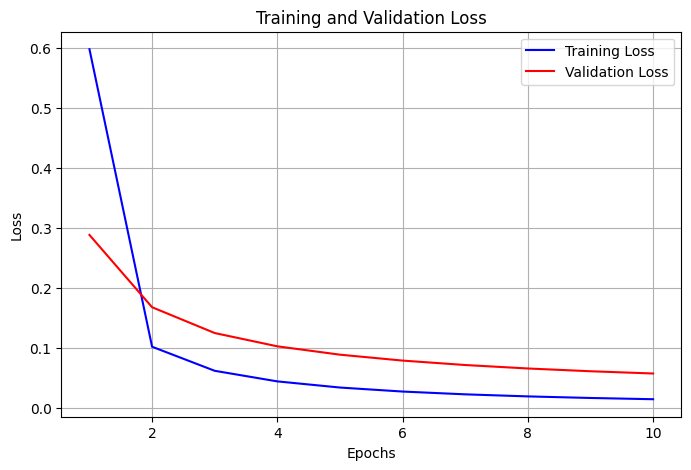

In [51]:
# Training Loss Visualisation
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(loss) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, loss, 'b-', label='Training Loss')
plt.plot(epochs, val_loss, 'r-', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

## 3. Evaluation and Final Predictions

<font color=red></font>

After training the model, it is essential to evaluate how well it performs on unseen data. Evaluation helps us understand whether the model has learned generalisable patterns or has simply memorised the training data.

In this section, we:
- Measure model performance using validation accuracy
- Analyse predictions at the individual data-point level
- Examine model behavior using diagnostic plots

### 3.1 Evaluation Metrics and Bias-Variance Tradeoff

<font color=red></font>

#### **3.1.1** Calculate Appropriate Evaluation Metrics to Assess Model Performance <font color=red></font>

For this multi-class classification problem, we use **accuracy** as the primary evaluation metric.

Accuracy measures the proportion of validation samples that are correctly classified by the model. Since the dataset is reasonably balanced across classes, accuracy provides a reliable indication of overall performance.

In [52]:
# Model Evaluation
# Overall loss and accuracy
val_loss, val_accuracy = model.evaluate(val_loader, verbose=1)
print(f"Validation Accuracy: {val_accuracy:.4f}")
print(f"Validation Loss: {val_loss:.4f}\n")

# Get true labels and predictions for detailed metrics
y_true = np.concatenate([np.argmax(labels.numpy(), axis=1) for _, labels in val_loader])
y_pred_probs = model.predict(val_loader)
y_pred = np.argmax(y_pred_probs, axis=1)

# Generate classification report
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

12/12 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.9806 - loss: 0.0574
Validation Accuracy: 0.9806
Validation Loss: 0.0574

12/12 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step
Classification Report:
                 precision    recall  f1-score   support

        crazing       1.00      1.00      1.00        60
      inclusion       1.00      0.88      0.94        60
        patches       1.00      1.00      1.00        60
 pitted_surface       0.97      1.00      0.98        60
rolled-in_scale       1.00      1.00      1.00        60
      scratches       0.92      1.00      0.96        60

       accuracy                           0.98       360
      macro avg       0.98      0.98      0.98       360
   weighted avg       0.98      0.98      0.98       360



#### **3.1.2** Dataset Diagnostics <font color=red></font>

Beyond accuracy, diagnostic analysis helps assess whether the model is underfitting, overfitting, or generalising well

Analyse this using training and validation loss trends, along with dataset class distribution.

In [53]:
# Training and Validation Loss Analysis
final_train_loss = history.history['loss'][-1]
final_val_loss = history.history['val_loss'][-1]
final_train_acc = history.history['accuracy'][-1]
final_val_acc = history.history['val_accuracy'][-1]

print("--- Dataset & Model Diagnostics ---")
print(f"Final Training Accuracy: {final_train_acc:.4f}")
print(f"Final Validation Accuracy: {final_val_acc:.4f}")
print(f"Final Training Loss: {final_train_loss:.4f}")
print(f"Final Validation Loss: {final_val_loss:.4f}")

loss_gap = final_val_loss - final_train_loss
print(f"\nLoss Gap (Validation - Training): {loss_gap:.4f}")

if loss_gap > 0.15:
    print("Diagnosis: Potential Overfitting (High Variance). The model performs significantly better on training data than validation data.")
elif final_train_acc < 0.85:
    print("Diagnosis: Potential Underfitting (High Bias). The model struggles to learn the underlying patterns in the training data.")
else:
    print("Diagnosis: Good Generalisation. The model has learned well and transfers its knowledge effectively to unseen validation data without significant overfitting.")


--- Dataset & Model Diagnostics ---
Final Training Accuracy: 0.9986
Final Validation Accuracy: 0.9806
Final Training Loss: 0.0145
Final Validation Loss: 0.0574

Loss Gap (Validation - Training): 0.0429
Diagnosis: Good Generalisation. The model has learned well and transfers its knowledge effectively to unseen validation data without significant overfitting.


### 3.2 Prediction Analysis

<font color=red></font>

Overall accuracy provides a summary metric, but it does not reveal how individual predictions contribute to that score.

To better understand model behavior, we examine predictions at the individual image level, highlighting both correct and incorrect classifications.

#### **3.2.1** Visualise the prediction on a few sample images from validation set <font color=red></font>

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


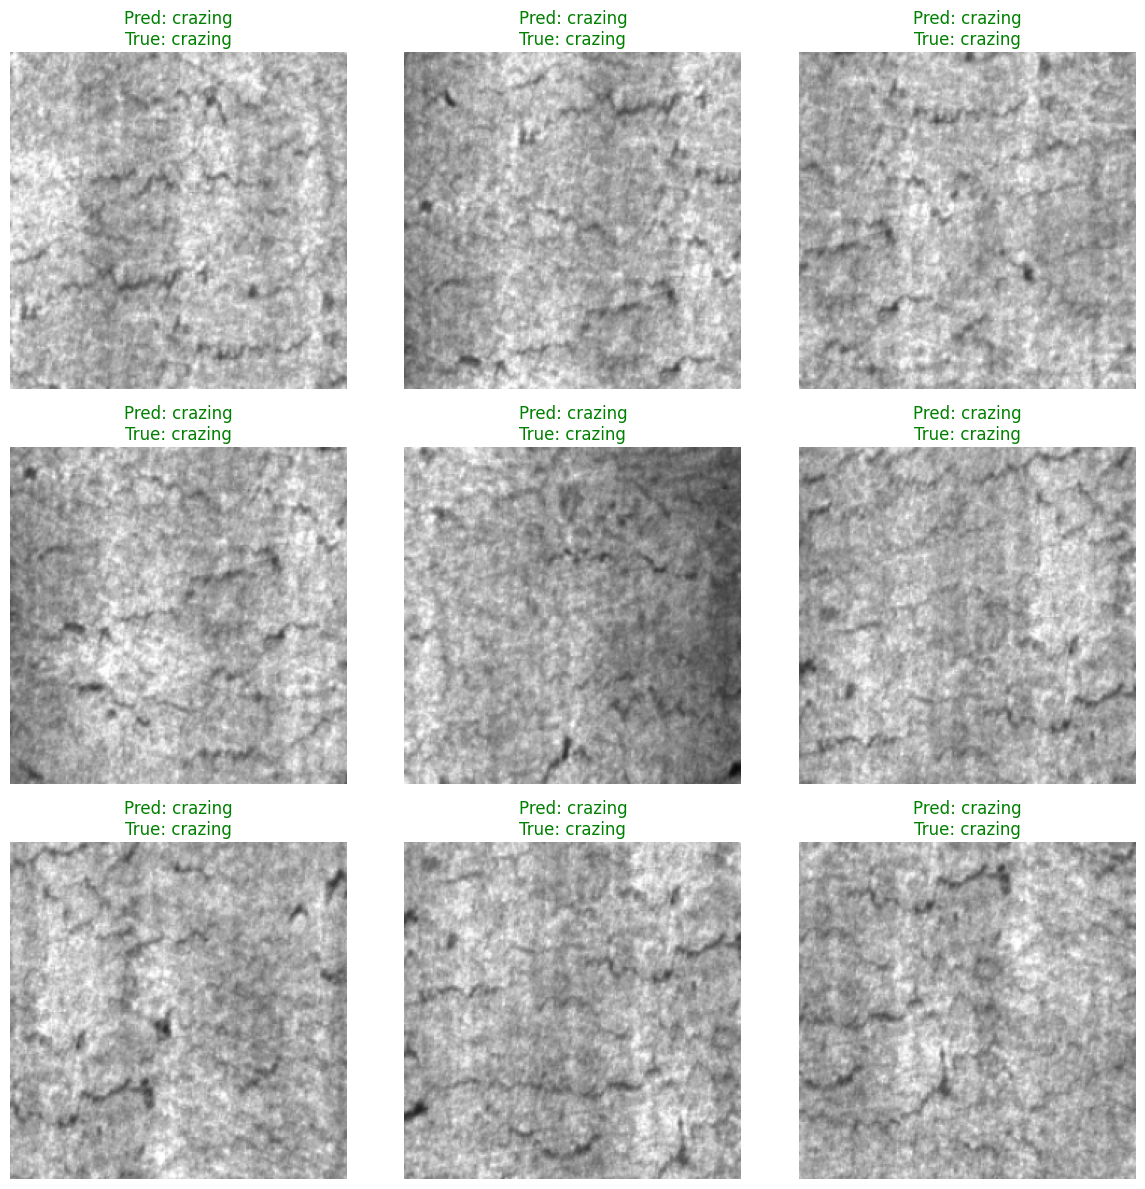

In [54]:
# Visualisation of Validation Predictions
# Getting a single batch of images and labels from the validation set
for images, labels in val_loader.take(1):
    preds = model.predict(images)
    pred_classes = np.argmax(preds, axis=1)
    true_classes = np.argmax(labels.numpy(), axis=1)

    plt.figure(figsize=(12, 12))
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)

        # Un-normalize image for display
        img = images[i].numpy()
        img = img * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]
        img = np.clip(img, 0, 1)

        plt.imshow(img)

        pred_label = class_names[pred_classes[i]]
        true_label = class_names[true_classes[i]]

        color = "green" if pred_classes[i] == true_classes[i] else "red"
        plt.title(f"Pred: {pred_label}\nTrue: {true_label}", color=color)
        plt.axis("off")

    plt.tight_layout()
    plt.show()
    break


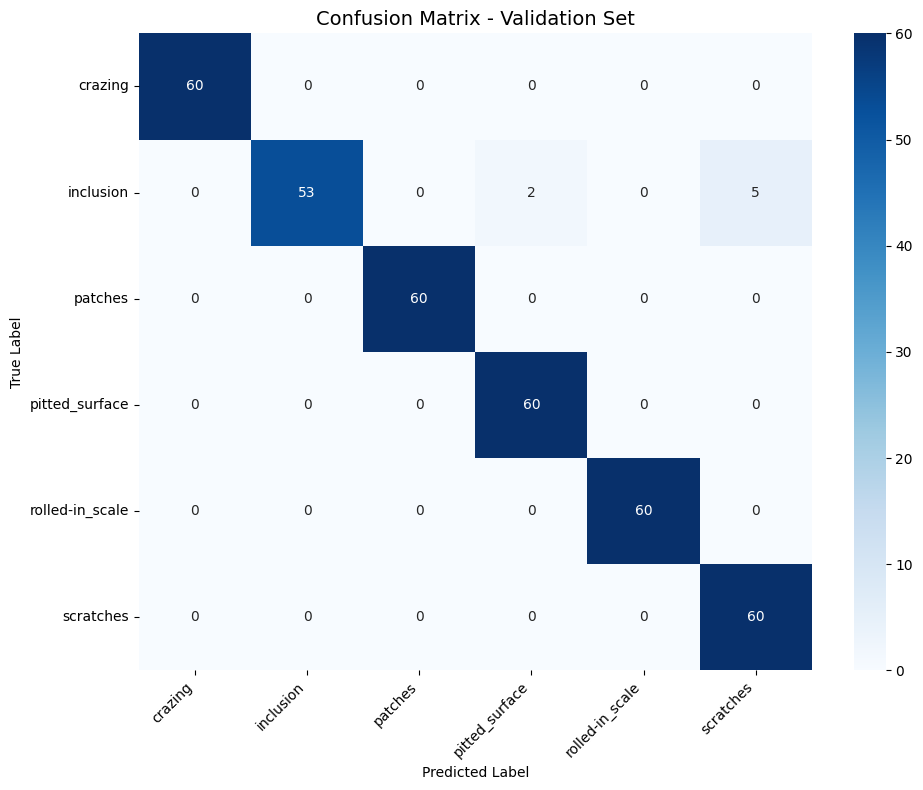


Misclassified Inclusion samples:
True: inclusion → Predicted: pitted_surface
True: inclusion → Predicted: scratches
True: inclusion → Predicted: scratches
True: inclusion → Predicted: scratches
True: inclusion → Predicted: scratches
True: inclusion → Predicted: scratches
True: inclusion → Predicted: pitted_surface


In [55]:
# Confusion Matrix to derive better conclusion
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Confusion Matrix - Validation Set', fontsize=14)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Print misclassification details for Inclusion
print("\nMisclassified Inclusion samples:")
inclusion_idx = class_names.index('inclusion')
for true, pred in zip(y_true, y_pred):
    if true == inclusion_idx and pred != true:
        print(f"True: inclusion → Predicted: {class_names[pred]}")

## 4 Conclusion

<font color =red>  </font>

### 4.1 Conclusion and insights

<font color =red>  </font>

#### **4.1.1** Conclude with the insights drawn and final outcomes and results. Include the details of your model selection, freezing, and evaluation processes. <font color =red>  </font>


Final Outcomes and Insights

**Model Selection**

I selected MobileNetV2 pretrained on ImageNet due to its excellent trade-off between accuracy and computational efficiency. Its lightweight architecture (depthwise separable convolutions and inverted residual blocks) makes it particularly suitable for industrial deployment scenarios where inference speed and hardware constraints are important.
Freezing Strategy

I employed a partial transfer learning approach by completely freezing the MobileNetV2 feature extractor and training only a custom classification head (GlobalAveragePooling2D + Dense layer with softmax). This decision was deliberate given the moderate size of the training set (1,441 images). Freezing preserved the rich low-level texture and edge features learned from ImageNet while significantly reducing the risk of overfitting.

**Quantitative Results**

The model achieved strong performance on the validation set:

Validation Accuracy: 98.06%
Validation Loss: 0.0574
Final Training Accuracy: 99.86% | Final Training Loss: 0.0145

The very small gap between training and validation loss (0.043) indicates excellent generalisation and a healthy bias-variance balance. There is no evidence of significant overfitting or underfitting.

**Error Analysis (Confusion Matrix)**

The confusion matrix reveals that the model performed almost perfectly across most classes:

Perfect classification (60/60) on crazing, patches, pitted_surface, rolled-in_scale, and scratches.
The only errors occurred in the inclusion class (53/60 correct → recall = 0.88).
5 inclusion samples were misclassified as scratches
2 inclusion samples were misclassified as pitted_surface


This pattern is visually understandable, as inclusions can sometimes appear as linear or irregular dark marks that resemble scratches or pitted regions.

**Key Insights**

Full freezing of MobileNetV2 worked extremely well for this texture-based industrial dataset.
The model generalises very strongly despite the relatively limited training data.
The remaining errors are concentrated in a single class (inclusion) and stem from inherent visual similarity rather than a modelling failure.

**Business Relevance**

This experiment demonstrates that a lightweight transfer learning pipeline can deliver near-perfect surface defect classification accuracy while remaining computationally efficient. Such a model can serve as a reliable and scalable alternative to purely manual inspection in steel manufacturing environments.

**Possible Improvements**

Collecting additional inclusion samples or applying targeted data augmentation for that class.
Light fine-tuning of the last few layers of the backbone (if higher inclusion recall is required in production).
Exploring class weighting or focal loss to further reduce the remaining inclusion errors.

Overall, the chosen approach (MobileNetV2 + full freezing + custom head) successfully solved the industrial surface defect classification problem with high reliability and practical efficiency.